In [8]:
   import numpy as np
   import matplotlib.pyplot as plt

   index = np.arange(10)
   signal = np.array([-1, 1, 2, 1, 0, -1, 1, 2, 1, -2])

In [9]:
def find_zero_crossings_no_zeros(signs: np.ndarray):
    """Find zero crossings in a sign array without zeros"""
    diff = np.diff(signs)
    i_cross_pos = np.where(diff > 0)[0]
    i_cross_neg = np.where(diff < 0)[0]
    return i_cross_pos, i_cross_neg


def propagate_signs_over_zeros(signs: np.ndarray):
    """Propagate non-zero signs over zero positions in the sign array."""

    signs_no_zeros = signs.copy()

    mask = signs_no_zeros != 0
    idx = np.where(mask, np.arange(len(signs_no_zeros)), 0)
    idx = np.maximum.accumulate(idx)
    signs_no_zeros = signs_no_zeros[idx]

    if signs_no_zeros[0] == 0:
        i_first_nonzero = np.where(signs != 0)[0]
        if len(i_first_nonzero) > 0:
            signs_no_zeros[: i_first_nonzero[0]] = signs[i_first_nonzero[0]]

    return signs_no_zeros


def find_zero_crossings(s: np.ndarray):
    """Find zero crossings in a 1D signal array."""

    s = np.asarray(s)
    if s.ndim != 1:
        raise ValueError("Input must be a 1D array")

    signs = np.sign(s).astype(int)
    i_zeros = np.where(signs == 0)[0]
    if i_zeros.size > 0:
        signs_no_zeros = propagate_signs_over_zeros(signs)
    else:
        signs_no_zeros = signs

    return find_zero_crossings_no_zeros(signs_no_zeros)

In [10]:
def test_find_zero_crossings():
    """Unit tests for find_zero_crossings function."""
    s = np.array([-1, 1, -1, 1, -1])
    # expected     +  -   +  -   +
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([0, 2]))
    assert np.array_equal(i_neg, np.array([1, 3]))

    s = np.array([-1, 0, 0, 1, 0, -1])
    # expected     -     +     -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([2]))
    assert np.array_equal(i_neg, np.array([4]))

    s = np.array([0, 0, 0, 1, 0, 0])
    # expected    no crossings
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([]))

    s = np.array([0, 0, 1, 0, -1, 0])
    # expected             -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([3]))

    s = np.array([0, 1, 0, 0, -1, 0])
    # expected             -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([3]))

    s = np.array([1, 0, 0, -1, 0, 0])
    # expected          -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([2]))


# Testing the function
try:
    test_find_zero_crossings()
    print("All tests passed.")
except AssertionError:
    raise  # propagate the error

All tests passed.


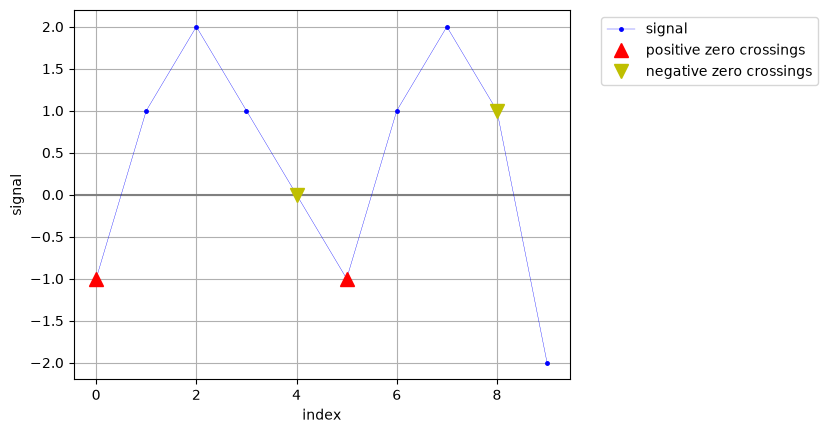

In [11]:
def plot_signal(i: np.ndarray, s: np.ndarray, color: str = "blue"):
    """Plot the signal as function of time/index with grid and zero line"""
    plt.axhline(y=0, color="gray", linestyle="-")  # before to be under the signal
    plt.plot(i, s, ".-", markersize=5, linewidth=0.25, color=color, label="signal")
    plt.ylabel("signal")
    plt.xlabel("index")


def plot_remarkable_points(t: np.ndarray, s: np.ndarray, format: str, label: str):
    """Plot remarkable points on a signal with format and label"""
    plt.plot(t, s, format, markersize=10, label=label)


def plot_positive_zero_crossings(i: np.ndarray, s: np.ndarray):
    """Plot positive zero crossings on a signal"""
    i_pos, _ = find_zero_crossings(s)
    plot_remarkable_points(i[i_pos], s[i_pos], "^r", "positive zero crossings")


def plot_negative_zero_crossings(i: np.ndarray, s: np.ndarray):
    """Plot negative zero crossings on a signal"""
    _, i_neg = find_zero_crossings(s)
    plot_remarkable_points(i[i_neg], s[i_neg], "vy", "negative zero crossings")


def plot_zero_crossings(i: np.ndarray, s: np.ndarray):
    """Plot all zero crossings on a signal"""
    plot_positive_zero_crossings(i, s)
    plot_negative_zero_crossings(i, s)


def display_signal_and_crossings(i: np.ndarray, s: np.ndarray):
    """Plot signal and zero crossings with legend outside the plot and grid"""
    plt.figure()
    plot_signal(i, s)
    plot_positive_zero_crossings(i, s)
    plot_negative_zero_crossings(i, s)
    # NOTE: legend outside does not work well with %matplotlib widget
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.grid(True)
    plt.show()


# Example usage
display_signal_and_crossings(index, signal)

## améliorer les docstrings de chaque fonction

In [12]:
def find_zero_crossings_no_zeros(signs: np.ndarray):
    """Find where the sign changes in an array of signs (only -1 and 1, no 0).

    Input: signs (1D array)
    Output: indices of positive crossings (-1 to 1) and negative crossings (1 to -1)
    """
    diff = np.diff(signs)  # difference between each value and the next one
    i_cross_pos = np.where(diff > 0)[0]  # sign goes from -1 to 1
    i_cross_neg = np.where(diff < 0)[0]  # sign goes from 1 to -1
    return i_cross_pos, i_cross_neg


def propagate_signs_over_zeros(signs: np.ndarray):
    """Replace each 0 by the last non-zero sign before it.
    If the array starts with zeros, they take the sign of the first non-zero value.

    Input: signs (1D array with -1, 0 and 1)
    Output: new array of signs without zeros
    """
    signs_no_zeros = signs.copy()  # copy so we don't change the original array

    mask = signs_no_zeros != 0  # True where the sign is not 0
    idx = np.where(mask, np.arange(len(signs_no_zeros)), 0)  # index if not 0, else 0
    idx = np.maximum.accumulate(idx)  # index of the last non-zero value seen so far
    signs_no_zeros = signs_no_zeros[idx]  # copy the last non-zero sign on the zeros

    # zeros at the beginning are still 0 (no value before them)
    if signs_no_zeros[0] == 0:
        i_first_nonzero = np.where(signs != 0)[0]
        if len(i_first_nonzero) > 0:  # if the signal is not only zeros
            signs_no_zeros[: i_first_nonzero[0]] = signs[i_first_nonzero[0]]

    return signs_no_zeros


def find_zero_crossings(s: np.ndarray):
    """Find the zero crossings of a 1D signal.

    Input: s (1D signal)
    Output: indices of positive crossings and indices of negative crossings
    (the index is the last point before the crossing)
    """
    s = np.asarray(s)  # transform into a numpy array
    if s.ndim != 1:
        raise ValueError("Input must be a 1D array")  # only 1D signals are accepted

    signs = np.sign(s).astype(int)  # -1, 0 or 1 for each value
    i_zeros = np.where(signs == 0)[0]  # positions of the zeros
    if i_zeros.size > 0:
        signs_no_zeros = propagate_signs_over_zeros(signs)  # remove the zeros
    else:
        signs_no_zeros = signs

    return find_zero_crossings_no_zeros(signs_no_zeros)

### a quoi servent les tests ?

Les tests vérifient que la fonction find_zero_crossings donne le bon résultat. On lui donne des petits signaux dont on connaît déjà la réponse, et on vérifie qu'elle trouve la même chose.

Si on modifie le code plus tard, il suffaudra juste relancer les tests. si un test ne passe plus, on sait tout de suite qu'il y a une erreur.

J'ai ajouté des cas qui n'étaient pas testés :
- un signal vide 
- un signal toujours positif 
- un signal avec seulement des zéros 
- un signal avec des nombres à virgule 
- un signal en 2D (la fonction doit renvoyer une erreur).

In [13]:
def test_find_zero_crossings():
    """Unit tests for find_zero_crossings function."""
    # original tests
    s = np.array([-1, 1, -1, 1, -1])
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([0, 2]))
    assert np.array_equal(i_neg, np.array([1, 3]))

    s = np.array([-1, 0, 0, 1, 0, -1])
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([2]))
    assert np.array_equal(i_neg, np.array([4]))

    s = np.array([0, 0, 0, 1, 0, 0])
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([]))

    s = np.array([0, 0, 1, 0, -1, 0])
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([3]))

    s = np.array([0, 1, 0, 0, -1, 0])
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([3]))

    s = np.array([1, 0, 0, -1, 0, 0])
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([2]))

    # my new tests
    # empty signal: no crossings
    i_pos, i_neg = find_zero_crossings(np.array([]))
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([]))

    # always positive: no crossings
    i_pos, i_neg = find_zero_crossings(np.array([1, 2, 3, 2]))
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([]))

    # only zeros: no crossings
    i_pos, i_neg = find_zero_crossings(np.array([0, 0, 0]))
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([]))

    # decimal values
    i_pos, i_neg = find_zero_crossings(np.array([-0.5, 0.2, -0.1]))
    assert np.array_equal(i_pos, np.array([0]))
    assert np.array_equal(i_neg, np.array([1]))

    # 2D signal: must give an error
    try:
        find_zero_crossings(np.array([[1, -1], [1, -1]]))
        assert False  # we should not arrive here
    except ValueError:
        pass


# Testing the function
try:
    test_find_zero_crossings()
    print("All tests passed.")
except AssertionError:
    raise  # propagate the error

All tests passed.


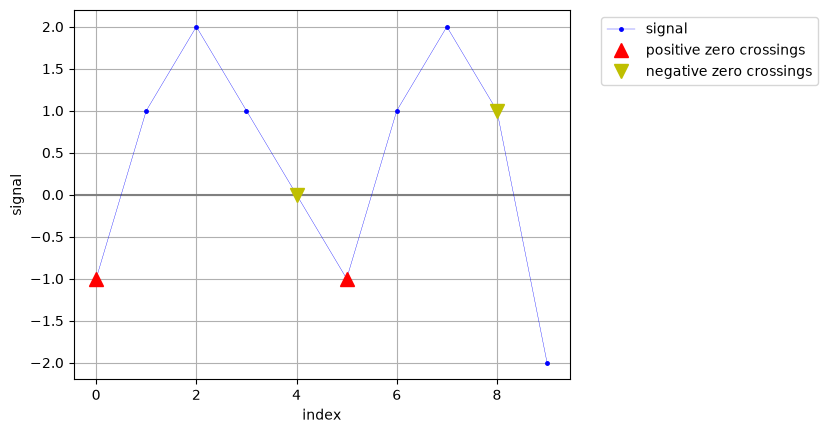

In [14]:
def plot_signal(i: np.ndarray, s: np.ndarray, color: str = "blue"):
    """Plot the signal (s) as a function of the index (i), with a line at 0."""
    plt.axhline(y=0, color="gray", linestyle="-")  # before to be under the signal
    plt.plot(i, s, ".-", markersize=5, linewidth=0.25, color=color, label="signal")
    plt.ylabel("signal")
    plt.xlabel("index")


def plot_remarkable_points(t: np.ndarray, s: np.ndarray, format: str, label: str):
    """Plot some points (t, s) with a marker format (ex: "^r") and a label for the legend."""
    plt.plot(t, s, format, markersize=10, label=label)


def plot_positive_zero_crossings(i: np.ndarray, s: np.ndarray):
    """Find and plot the positive zero crossings (red triangles)."""
    i_pos, _ = find_zero_crossings(s)
    plot_remarkable_points(i[i_pos], s[i_pos], "^r", "positive zero crossings")


def plot_negative_zero_crossings(i: np.ndarray, s: np.ndarray):
    """Find and plot the negative zero crossings (yellow triangles)."""
    _, i_neg = find_zero_crossings(s)
    plot_remarkable_points(i[i_neg], s[i_neg], "vy", "negative zero crossings")


def plot_zero_crossings(i: np.ndarray, s: np.ndarray):
    """Plot the positive and the negative zero crossings."""
    plot_positive_zero_crossings(i, s)
    plot_negative_zero_crossings(i, s)


def display_signal_and_crossings(i: np.ndarray, s: np.ndarray):
    """Make a new figure with the signal and its zero crossings, then show it."""
    plt.figure()
    plot_signal(i, s)
    plot_zero_crossings(i, s)
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")  # legend outside the plot
    plt.grid(True)
    plt.show()


# Example usage
display_signal_and_crossings(index, signal)

## Maxima et minima locaux

In [15]:
def find_local_extrema(s: np.ndarray):
    """Find the local maxima and minima of a 1D signal.

    Input: s (1D signal)
    Output: indices of the local maxima and indices of the local minima
    """
    slope = np.diff(s)  # slope between each point and the next one
    i_pos, i_neg = find_zero_crossings(slope)  # where the slope changes sign
    i_local_max = i_neg + 1  # slope goes from + to - : maximum (+1 because of np.diff)
    i_local_min = i_pos + 1  # slope goes from - to + : minimum
    return i_local_max, i_local_min


def plot_local_maxima(i: np.ndarray, s: np.ndarray):
    """Find and plot the local maxima."""
    i_max, _ = find_local_extrema(s)
    plot_remarkable_points(i[i_max], s[i_max], "or", "local maxima")


def plot_local_minima(i: np.ndarray, s: np.ndarray):
    """Find and plot the local minima."""
    _, i_min = find_local_extrema(s)
    plot_remarkable_points(i[i_min], s[i_min], "og", "local minima")


def display_signal_and_extrema(i: np.ndarray, s: np.ndarray):
    """Make a new figure with the signal and its local maxima and minima, then show it."""
    plt.figure()
    plot_signal(i, s)
    plot_local_maxima(i, s)
    plot_local_minima(i, s)
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.grid(True)
    plt.show()

In [16]:
def test_find_local_extrema():
    """Unit test for find_local_extrema function."""
    s = np.array([-1, 1, 2, 1, 0, -1, 1, 2, 1, -2])
    i_max, i_min = find_local_extrema(s)
    assert np.array_equal(i_max, np.array([2, 7]))
    assert np.array_equal(i_min, np.array([5]))


test_find_local_extrema()
print("All tests passed.")

All tests passed.


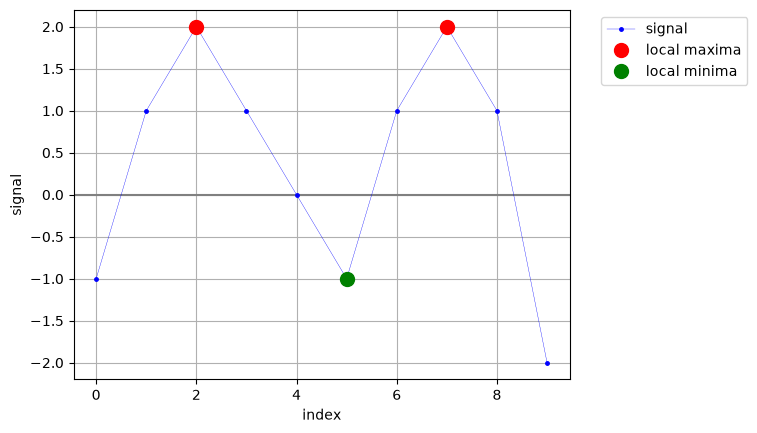

In [17]:
display_signal_and_extrema(index, signal)